# Import libraries

In [15]:
import os
import re
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Prepare VisioWell results in a dataframe

In [16]:
# find name of files
path_results = r"../divisiontimes" #"../../Final"
name_scenes = os.listdir(path_results)
name_scenes = [scene for scene in name_scenes if scene.endswith(".csv")]
print(f"Before deletion: {name_scenes}")
# exclude csv files that are not going to be used here
if "output_MB03102025_new_HPC_3000.csv" in name_scenes:
    name_scenes.remove("output_MB03102025_new_HPC_3000.csv")
    print("Removed output_MB03102025_new_HPC_3000.csv from name_scenes")


print(f"After deletion: {name_scenes}")


Before deletion: ['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB01092025_Scene003.csv', 'output_MB01092025_Scene004.csv', 'output_MB01092025_Scene005.csv', 'output_MB01092025_Scene006.csv', 'output_MB01092025_Scene007.csv', 'output_MB01092025_Scene008.csv', 'output_MB01092025_Scene009.csv', 'output_MB01092025_Scene010.csv', 'output_MB03102025_HPC_3000.csv', 'output_MB03102025_HPC_epp.csv', 'output_MB03102025_HSC_2000.csv', 'output_MB03102025_HSC_epp.csv', 'output_MB03102025_LMPP_epp.csv', 'output_MB03102025_MPP_epp.csv', 'output_MB07082025_Scene001.csv', 'output_MB07082025_Scene002.csv', 'output_MB07082025_Scene003.csv', 'output_MB07082025_Scene004.csv', 'output_MB07082025_Scene005.csv', 'output_MB07082025_Scene006.csv', 'output_MB07082025_Scene007.csv', 'output_MB07082025_Scene008.csv', 'output_MB07082025_Scene009.csv', 'output_MB07082025_Scene010.csv']
After deletion: ['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB010920

In [17]:
# Dictionary in which the experiments are the keys
# and the values are the list of scenes corresponding to each experiment (not loaded yet)
exp_dict = defaultdict(list)
for scene in name_scenes:
    # extract key experiment
    m = re.match(r'output_(MB\d+)', scene)
    if m:
        exp_key = m.group(1)
        exp_dict[exp_key].append(scene)

# order file list
for k in exp_dict:
    exp_dict[k] = sorted(exp_dict[k])

# visualize dict
print(f"Final dictionary: {exp_dict}\n")
# count elements in dict
print("Number of scenes per experiment:")
for key, files in exp_dict.items():
    print(f"{key}: {len(files)} scenes")


Final dictionary: defaultdict(<class 'list'>, {'MB01092025': ['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB01092025_Scene003.csv', 'output_MB01092025_Scene004.csv', 'output_MB01092025_Scene005.csv', 'output_MB01092025_Scene006.csv', 'output_MB01092025_Scene007.csv', 'output_MB01092025_Scene008.csv', 'output_MB01092025_Scene009.csv', 'output_MB01092025_Scene010.csv'], 'MB03102025': ['output_MB03102025_HPC_3000.csv', 'output_MB03102025_HPC_epp.csv', 'output_MB03102025_HSC_2000.csv', 'output_MB03102025_HSC_epp.csv', 'output_MB03102025_LMPP_epp.csv', 'output_MB03102025_MPP_epp.csv'], 'MB07082025': ['output_MB07082025_Scene001.csv', 'output_MB07082025_Scene002.csv', 'output_MB07082025_Scene003.csv', 'output_MB07082025_Scene004.csv', 'output_MB07082025_Scene005.csv', 'output_MB07082025_Scene006.csv', 'output_MB07082025_Scene007.csv', 'output_MB07082025_Scene008.csv', 'output_MB07082025_Scene009.csv', 'output_MB07082025_Scene010.csv']})

Number of scenes per e

In [18]:
def add_condition_column(name_scenes,exp, path_results, equivalence_dict):
    # obtain a flat df with a new column "Condition" and "Exp_name" for each scene in name_scenes
    global_df = []
    for scene in name_scenes:
        df = pd.read_csv(os.path.join(path_results, scene))
        name_key = equivalence_dict[scene]
        df["Condition"] = name_key
        df["Exp_name"] = exp
        global_df.append(df)
    global_flat_df = pd.concat(global_df, ignore_index=True)
    return global_flat_df
equivalence_dict = {'output_MB07082025_Scene001.csv':"BMS-265246",
                    'output_MB07082025_Scene002.csv':"Palbociclib",
                    'output_MB07082025_Scene003.csv':"Venetoclax",
                    'output_MB07082025_Scene004.csv':"JQ-1",
                    'output_MB07082025_Scene005.csv':"JQ-1",
                    'output_MB07082025_Scene006.csv':"Venetoclax",
                    'output_MB07082025_Scene007.csv':"Palbociclib",
                    'output_MB07082025_Scene008.csv':"BMS-265246",
                    'output_MB07082025_Scene009.csv':"Control",
                    'output_MB07082025_Scene010.csv':"Control",
                    'output_MB01092025_Scene001.csv':"BMS-265246",
                    'output_MB01092025_Scene002.csv':"Palbociclib",
                    'output_MB01092025_Scene003.csv':"Venetoclax",
                    'output_MB01092025_Scene004.csv':"JQ-1",
                    'output_MB01092025_Scene005.csv':"JQ-1",
                    'output_MB01092025_Scene006.csv':"Venetoclax",
                    'output_MB01092025_Scene007.csv':"Palbociclib",
                    'output_MB01092025_Scene008.csv':"BMS-265246",
                    'output_MB01092025_Scene009.csv':"Control",
                    'output_MB01092025_Scene010.csv':"Control",
                    'output_MB03102025_HPC_3000.csv':"HPC",
                    'output_MB03102025_HPC_epp.csv':"HPC",
                    'output_MB03102025_HSC_2000.csv':"HSC",
                    'output_MB03102025_HSC_epp.csv':"HSC",
                    'output_MB03102025_MPP_epp.csv':"MPP",
                    'output_MB03102025_LMPP_epp.csv':"LMPP",
                    'output_MB11092025_HPC.csv':"HPC",
                    'output_MB11092025_HSC.csv':"HSC",
                    'output_MB11092025_MPP.csv':"MPP",
                    'output_MB11092025_LMPP.csv':"LMPP"
                    }

print(exp_dict.keys())

# obtain dataframes for each experiment and concatenate them in a global dataframe
all_dfs = []
for exp, name_scenes in exp_dict.items():
    print(f"The scenes contained in {exp} are:\n{name_scenes}")
    df_flat = add_condition_column(name_scenes, exp, path_results, equivalence_dict)
    all_dfs.append(df_flat)

global_flat_df = pd.concat(all_dfs, ignore_index=True)

print(global_flat_df.head())
len(global_flat_df)

dict_keys(['MB01092025', 'MB03102025', 'MB07082025'])
The scenes contained in MB01092025 are:
['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB01092025_Scene003.csv', 'output_MB01092025_Scene004.csv', 'output_MB01092025_Scene005.csv', 'output_MB01092025_Scene006.csv', 'output_MB01092025_Scene007.csv', 'output_MB01092025_Scene008.csv', 'output_MB01092025_Scene009.csv', 'output_MB01092025_Scene010.csv']
The scenes contained in MB03102025 are:
['output_MB03102025_HPC_3000.csv', 'output_MB03102025_HPC_epp.csv', 'output_MB03102025_HSC_2000.csv', 'output_MB03102025_HSC_epp.csv', 'output_MB03102025_LMPP_epp.csv', 'output_MB03102025_MPP_epp.csv']
The scenes contained in MB07082025 are:
['output_MB07082025_Scene001.csv', 'output_MB07082025_Scene002.csv', 'output_MB07082025_Scene003.csv', 'output_MB07082025_Scene004.csv', 'output_MB07082025_Scene005.csv', 'output_MB07082025_Scene006.csv', 'output_MB07082025_Scene007.csv', 'output_MB07082025_Scene008.csv', 'output_MB

18974

# Prepare groundtruth

In [19]:
folder_gt = r"../groundtruth"
name_file_gt = r"TT_divisiontimes.xlsx"
name_sheet_list = ["MB07082025", "MB03102025"]
file_path = os.path.join(folder_gt, name_file_gt)
gt_dict = pd.read_excel(file_path, sheet_name=name_sheet_list)
combined_df = pd.concat(gt_dict.values(), ignore_index=True)


In [20]:
print(global_flat_df.head())

                                            ResultID CellType  ColonySize  \
0  output_experiment_sherlock_OCI_Drug_Screening-...      oci         1.0   
1  output_experiment_sherlock_OCI_Drug_Screening-...      oci        15.0   
2  output_experiment_sherlock_OCI_Drug_Screening-...      oci         1.0   
3  output_experiment_sherlock_OCI_Drug_Screening-...      oci        32.0   
4  output_experiment_sherlock_OCI_Drug_Screening-...      oci         3.0   

     T1  T2.1  T2.2  T3.1  T3.2  T3.3  T3.4  ...  Indic_std  Indic_std-9  \
0   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...        NaN          NaN   
1  25.0  40.0  45.0  60.0  60.0  60.0  60.0  ...        NaN          NaN   
2   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...        NaN          NaN   
3   5.0  20.0  25.0  35.0  40.0  40.0  40.0  ...        NaN          NaN   
4   5.0  35.0  35.0  50.0  75.0   NaN   NaN  ...        NaN          NaN   

   Osc_index  Osc_height_index  Osc_index-9  Osc_height_index-9  GenDiscr  \
0  

In [21]:
# exclude rows with all NaN values in T1, T2.1, T2.2, T3.1, T3.2, T3.3, T3.4
# I expect 50 rows for MB07082025 and 33 rows for MB03102025, so 83 in total
print(combined_df.head())
cols_to_check = ['T1', 'T2.1', 'T2.2', 'T3.1', 'T3.2', 'T3.3', 'T3.4']
for col in cols_to_check:
    combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')
combined_df = combined_df.dropna(subset=cols_to_check, how='all')
len(combined_df)

                 Name    T1  T2.1  T2.2  T3.1  T3.2  T3.3  T3.4  \
0  TR1-A01_tile176_b4  26.0  67.0  76.0   NaN   NaN   NaN   NaN   
1  TR1-A01_tile163_a2   4.0  25.0  29.0  41.0  42.0  47.0  48.0   
2  TR1-A01_tile068_b4   9.0  22.0  23.0  40.0  41.0  46.0  50.0   
3  TR1-A01_tile069_b2  22.0  44.0  49.0  65.0  69.0  71.0  85.0   
4  TR1-A01_tile051_a1   7.0  28.0  29.0  51.0  52.0  60.0  60.0   

  NB: time of division from algorithm need to be +1 or +2 based on time frame  \
0                                     Hiding of cell                            
1  first division very soon (correction deletes t...                            
2                            overimposition of cells                            
3                                                NaN                            
4                            overimposition of cells                            

   Unnamed: 9  \
0         NaN   
1         NaN   
2         NaN   
3         NaN   
4         NaN   

  NB: H

83

In [22]:
# exclude experiment 01092025 and 11092025
df_pratic = global_flat_df[~global_flat_df["Exp_name"].isin(["MB01092025", "MB11092025"])]
print(df_pratic.columns)
print(df_pratic["ResultID"].iloc[1000])
combined_df["Name"].iloc[60]

Index(['ResultID', 'CellType', 'ColonySize', 'T1', 'T2.1', 'T2.2', 'T3.1',
       'T3.2', 'T3.3', 'T3.4', 'Indic_exact', 'Indic_exact-9', 'Indic_std',
       'Indic_std-9', 'Osc_index', 'Osc_height_index', 'Osc_index-9',
       'Osc_height_index-9', 'GenDiscr', 'Trust_index', 'Condition',
       'Exp_name'],
      dtype='object')
output_experiment_sherlock_MB_251003_cord_blood_34-01(HPC_epp)_tile064_a1


'(HPC_3000)_tile004_c1'

In [23]:
# Exclude HSC, MPP, LMPP
print(combined_df.shape)
flag_drop = True
if flag_drop:
    pattern_to_drop = r'^\((HSC_2000|LMPP_epp|MPP_epp)\)'
    rows_to_drop = combined_df[combined_df['Name'].str.contains(pattern_to_drop, regex=True)].index
    combined_df = combined_df.drop(index=rows_to_drop)
print(combined_df.shape)


(83, 11)
(64, 11)


C:\Users\tizia\AppData\Local\Temp\ipykernel_43560\2546201420.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  rows_to_drop = combined_df[combined_df['Name'].str.contains(pattern_to_drop, regex=True)].index


12159
7068


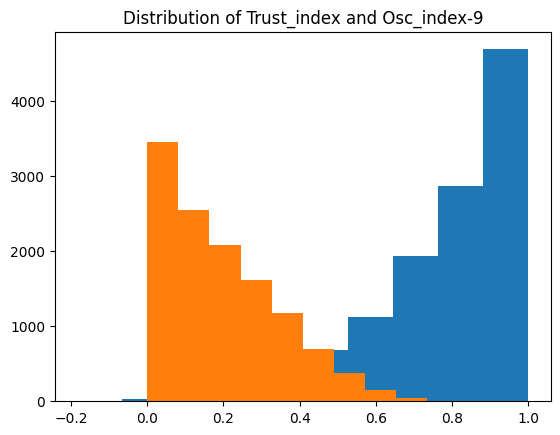

In [24]:
# Filtering based on Trust_index > th1 and Osc_index-9 < th2

print(len(df_pratic))
plt.hist(df_pratic["Trust_index"])
plt.hist(df_pratic["Osc_index-9"])
plt.title("Distribution of Trust_index and Osc_index-9")

filtered_df = df_pratic[(df_pratic["Trust_index"]>0)&(df_pratic["Osc_index-9"] < 0.2)]
print(len(filtered_df))

df_pratic = filtered_df




# Find correspondances between the naming convention used for VisioWell results and the groundtruth

In [25]:
# transform VisioWell naming keys to match groundtruth naming keys
def extract_key_resultid_flexible(x):
    if not isinstance(x, str):
        return None
    # format1: TR followed by number-letter, followed by anything, then _tile and something else
    match_tr = re.search(r'(TR\d+-[A-Z]\d+.*?_tile\d+_[a-zA-Z0-9]+)', x)
    if match_tr:
        return match_tr.group()
    # format2: HPC / HSC / LMPP / MPP 
    match_hpc = re.search(
    r'(\((HPC_\d+|HPC_epp|HSC_\d+|HSC_epp|LMPP_epp|MPP_epp)\)_tile\d+_[a-zA-Z0-9]+)',
    x
)
    if match_hpc:
        return match_hpc.group(1)
    return None

df_pratic = df_pratic.copy()
df_pratic['key'] = df_pratic['ResultID'].apply(extract_key_resultid_flexible)


In [26]:
assert(len(df_pratic['key'].unique()) == len(df_pratic))  # check that all keys are unique
assert(len(combined_df['Name'].unique()) == len(combined_df))  # check that all names are unique

# reset index
df_pratic = df_pratic.reset_index(drop=True)
combined_df = combined_df.reset_index(drop=True)
# find common keys
common_keys = set(df_pratic['key']).intersection(set(combined_df['Name']))
print(len(common_keys))
# select corresponding rows
df_pratic_matches = df_pratic[df_pratic['key'].isin(common_keys)]
combined_df_matches = combined_df[combined_df['Name'].isin(common_keys)]


29


In [27]:
print(df_pratic_matches["key"].head())
print(combined_df_matches["Name"].head())



8      (HPC_3000)_tile004_c1
18     (HPC_3000)_tile008_e2
32     (HPC_3000)_tile019_c2
77     (HPC_3000)_tile033_d1
150    (HPC_3000)_tile053_b4
Name: key, dtype: object
3     TR1-A01_tile069_b2
6     TR1-A01_tile112_a4
8     TR1-A01_tile043_d1
9     TR1-A01_tile081_b4
11    TR7-B02_tile082_a4
Name: Name, dtype: object


In [28]:
cols_to_diff = ['T1', 'T2.1', 'T2.2', 'T3.1', 'T3.2', 'T3.3', 'T3.4']
df_pratic_matches = df_pratic_matches.sort_values('key').reset_index(drop=True)
combined_df_matches = combined_df_matches.sort_values('Name').reset_index(drop=True)
print(len(df_pratic_matches))
print(len(combined_df_matches))
print(df_pratic_matches["key"].loc[0:10])
print(combined_df_matches["Name"].loc[0:10])

# add 1 for results from VisioWell -  ERROR: DO NOT DO IT
#mask1 = df_pratic_matches["Exp_name"] == "MB07082025"
#df_pratic_matches.loc[mask1, cols_to_diff] += 1
#mask2 = df_pratic_matches["Exp_name"] == "MB03102025"
#  df_pratic_matches.loc[mask2, cols_to_diff] += 0.5

# compute differences
diff_values  = df_pratic_matches[cols_to_diff]- combined_df_matches[cols_to_diff]
print(diff_values.head())

diff_df = pd.concat(
    [df_pratic_matches[['key', 'Condition']], diff_values],
    axis=1
)
print(diff_df.head())


29
29
0     (HPC_3000)_tile004_c1
1     (HPC_3000)_tile008_e2
2     (HPC_3000)_tile019_c2
3     (HPC_3000)_tile033_d1
4     (HPC_3000)_tile053_b4
5     (HPC_3000)_tile094_d4
6        TR1-A01_tile043_d1
7        TR1-A01_tile069_b2
8        TR1-A01_tile081_b4
9        TR1-A01_tile112_a4
10       TR3-A03_tile040_e2
Name: key, dtype: object
0     (HPC_3000)_tile004_c1
1     (HPC_3000)_tile008_e2
2     (HPC_3000)_tile019_c2
3     (HPC_3000)_tile033_d1
4     (HPC_3000)_tile053_b4
5     (HPC_3000)_tile094_d4
6        TR1-A01_tile043_d1
7        TR1-A01_tile069_b2
8        TR1-A01_tile081_b4
9        TR1-A01_tile112_a4
10       TR3-A03_tile040_e2
Name: Name, dtype: object
     T1  T2.1  T2.2  T3.1  T3.2  T3.3  T3.4
0  -1.0  -1.5   0.0   0.5  -0.5  -1.5  -1.5
1 -34.5 -12.5   NaN   NaN   NaN   NaN   NaN
2  -1.5  -1.0  -1.5   0.5  -0.5  -0.5   NaN
3   1.0  -1.5   NaN   NaN   NaN   NaN   NaN
4  -0.5  -1.0  -1.5   0.5   0.0   0.0  -0.5
                     key Condition    T1  T2.1  T2.2  T3.1  T3.

In [29]:
#print(df_pratic_matches.loc[mask2,"key"])

# Plot errors

key          (HPC_3000)_tile008_e2
Condition                      HPC
T1                           -34.5
T2.1                         -12.5
T2.2                           NaN
T3.1                           NaN
T3.2                           NaN
T3.3                           NaN
T3.4                           NaN
Name: 1, dtype: object
                   key Condition  T1  T2.1  T2.2  T3.1  T3.2  T3.3  T3.4
24  TR9-C01_tile008_a4   Control NaN   NaN   NaN   NaN   NaN   NaN   NaN


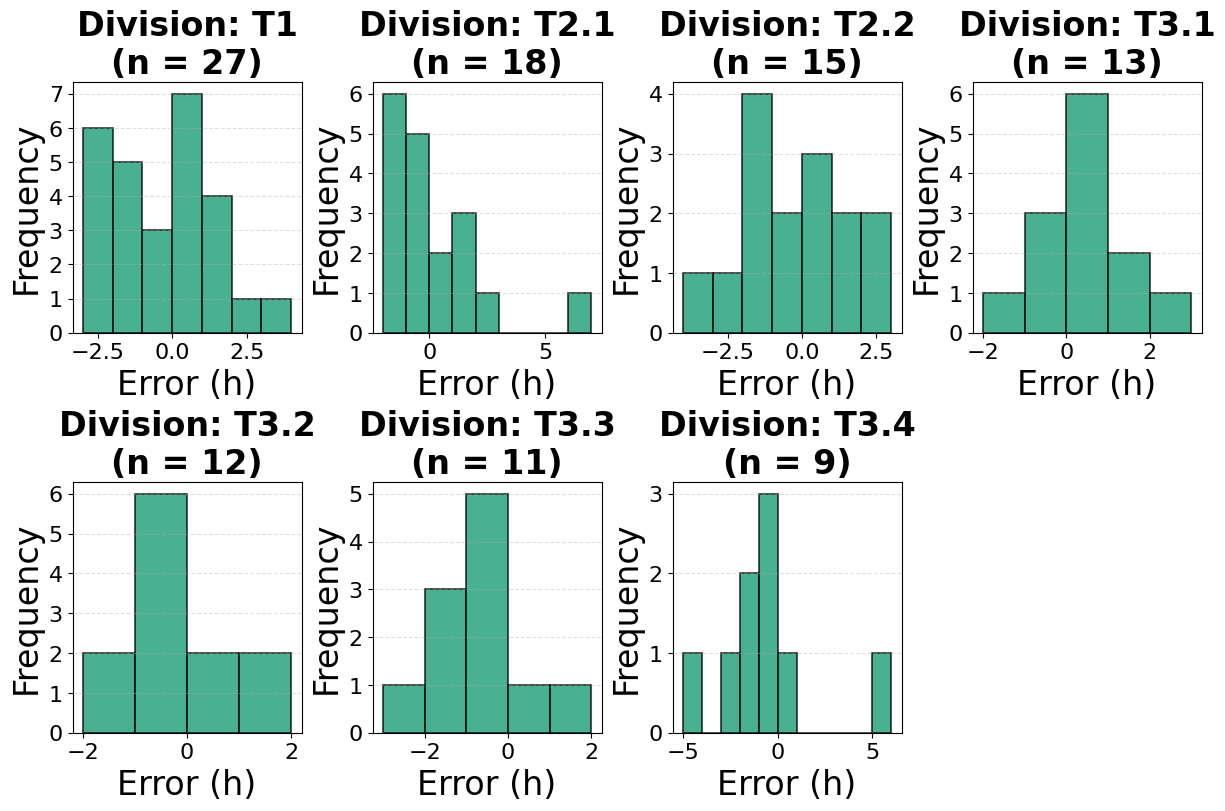

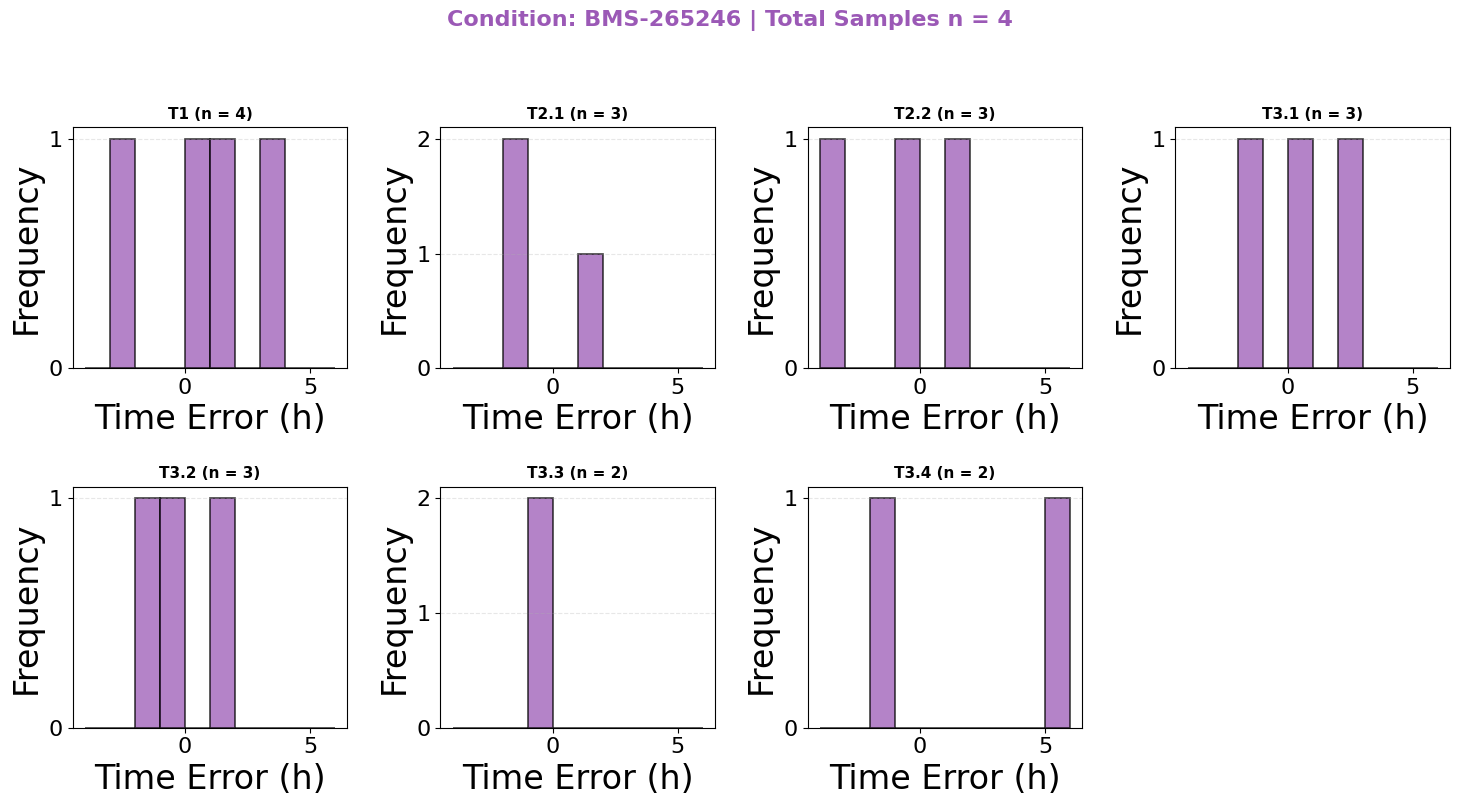

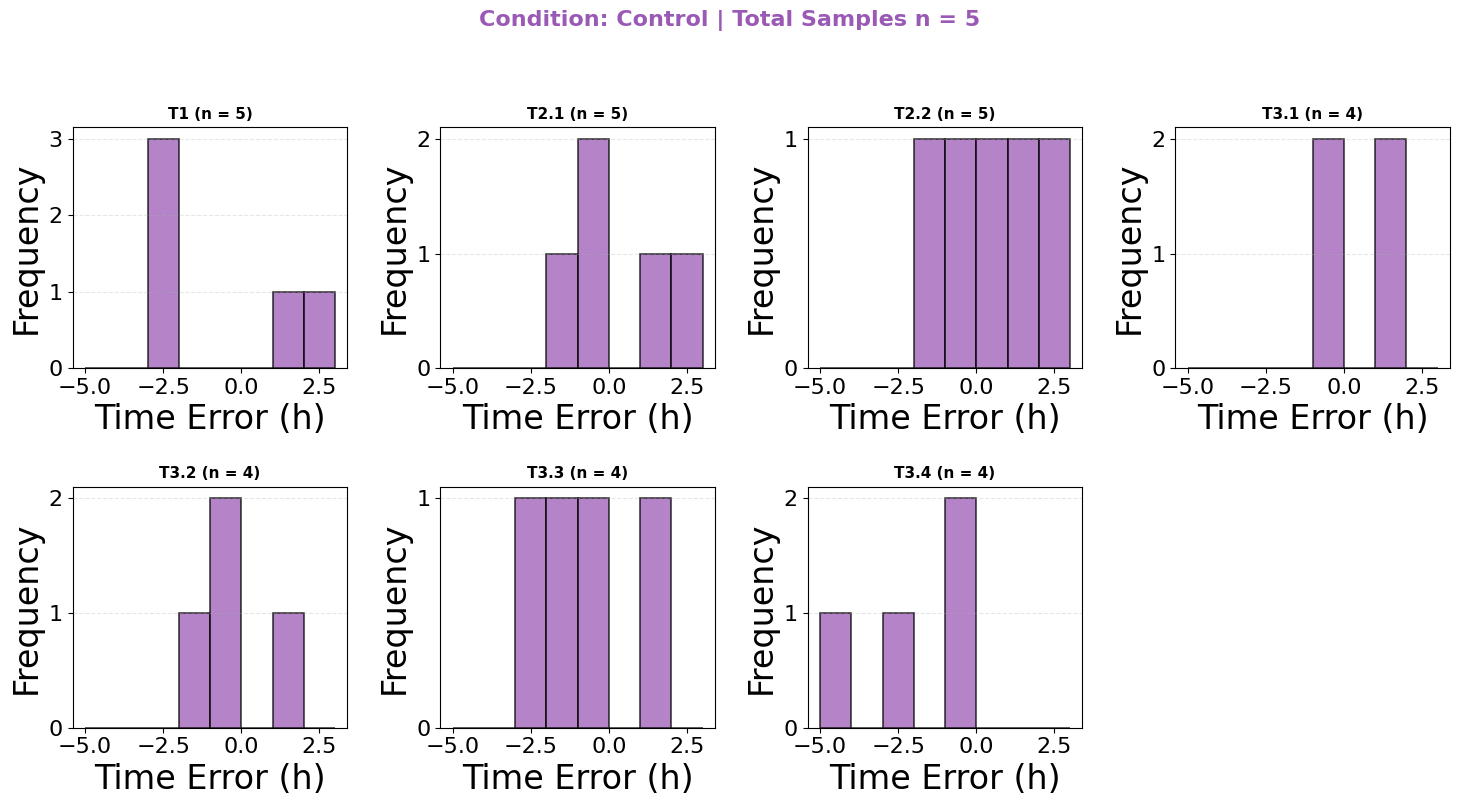

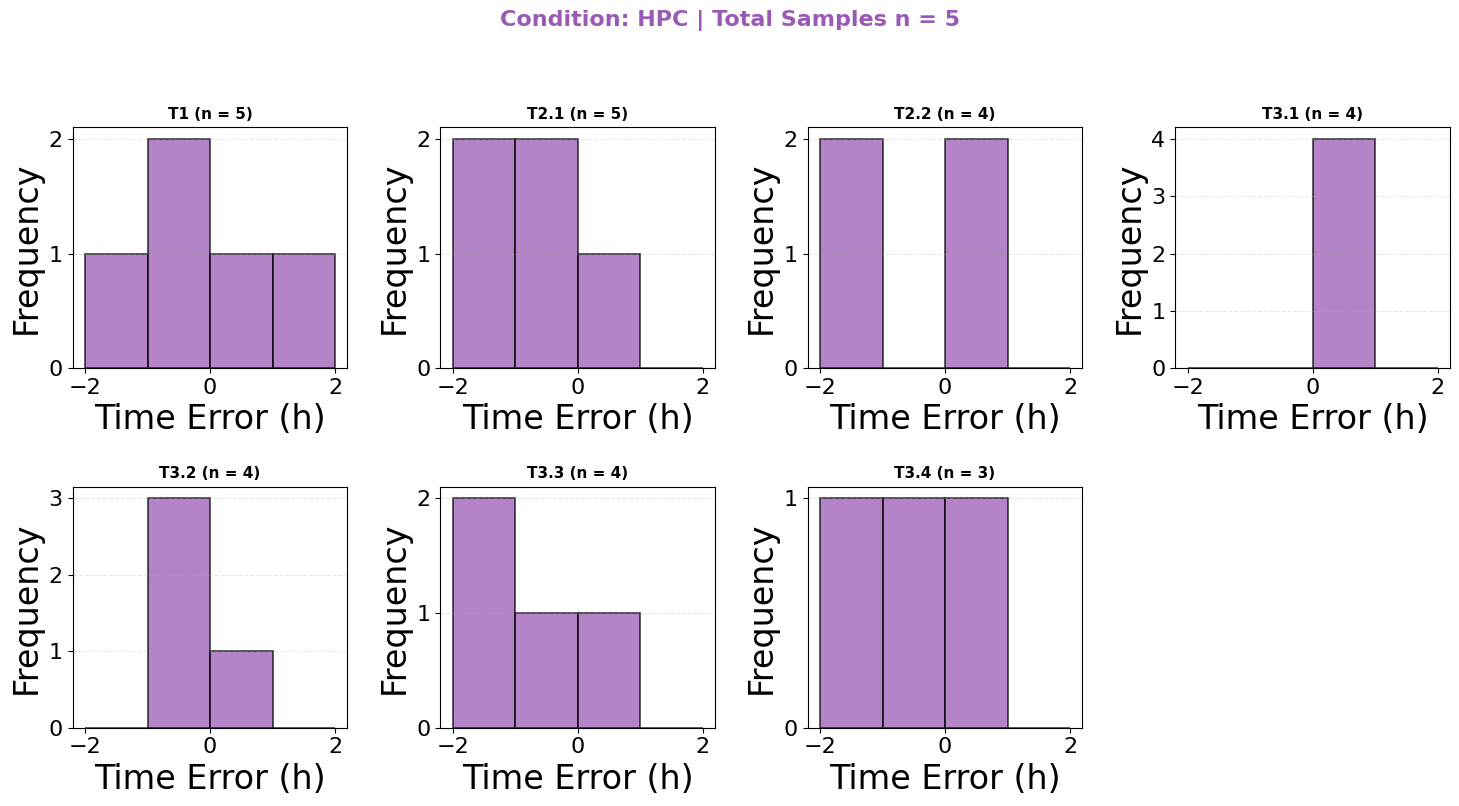

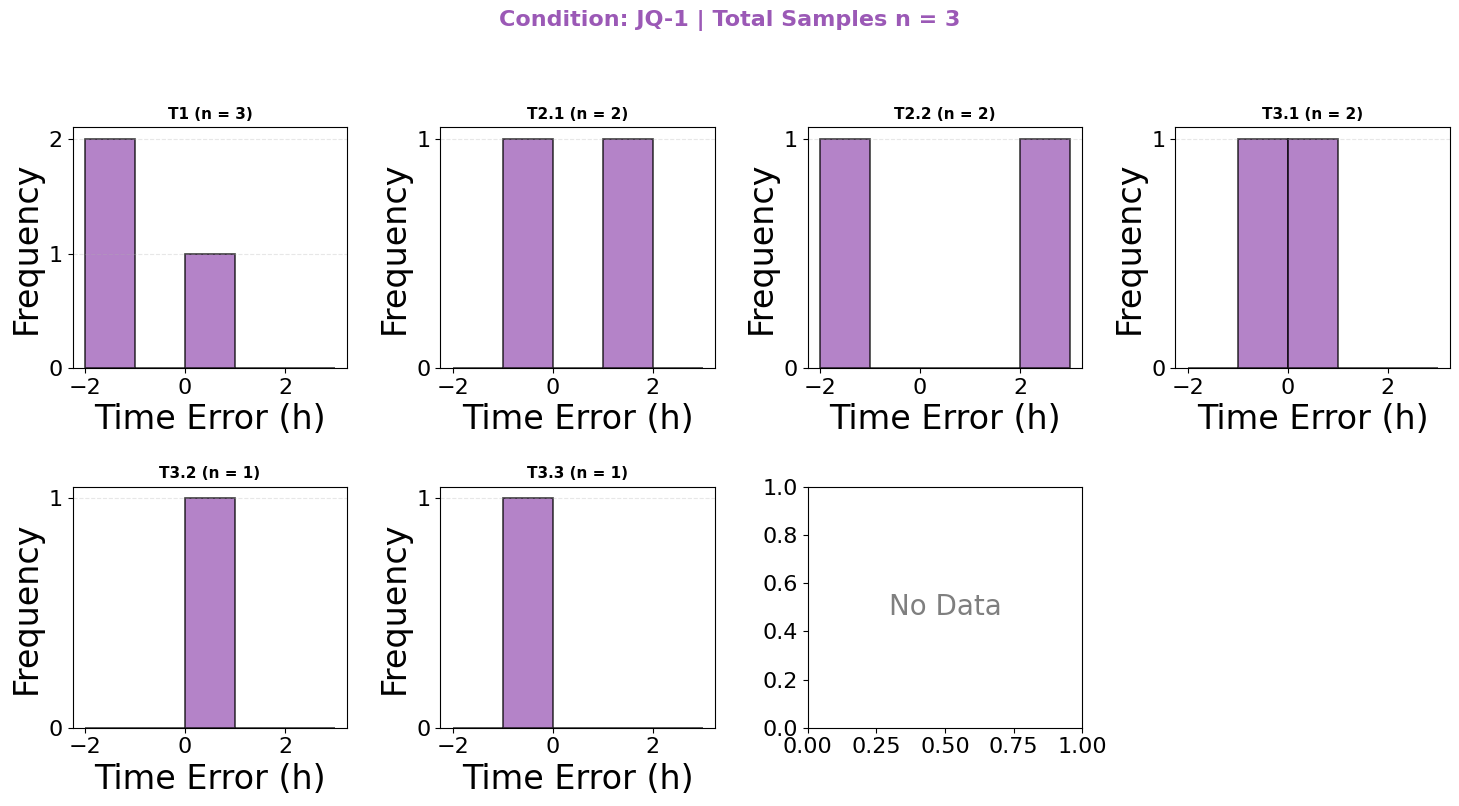

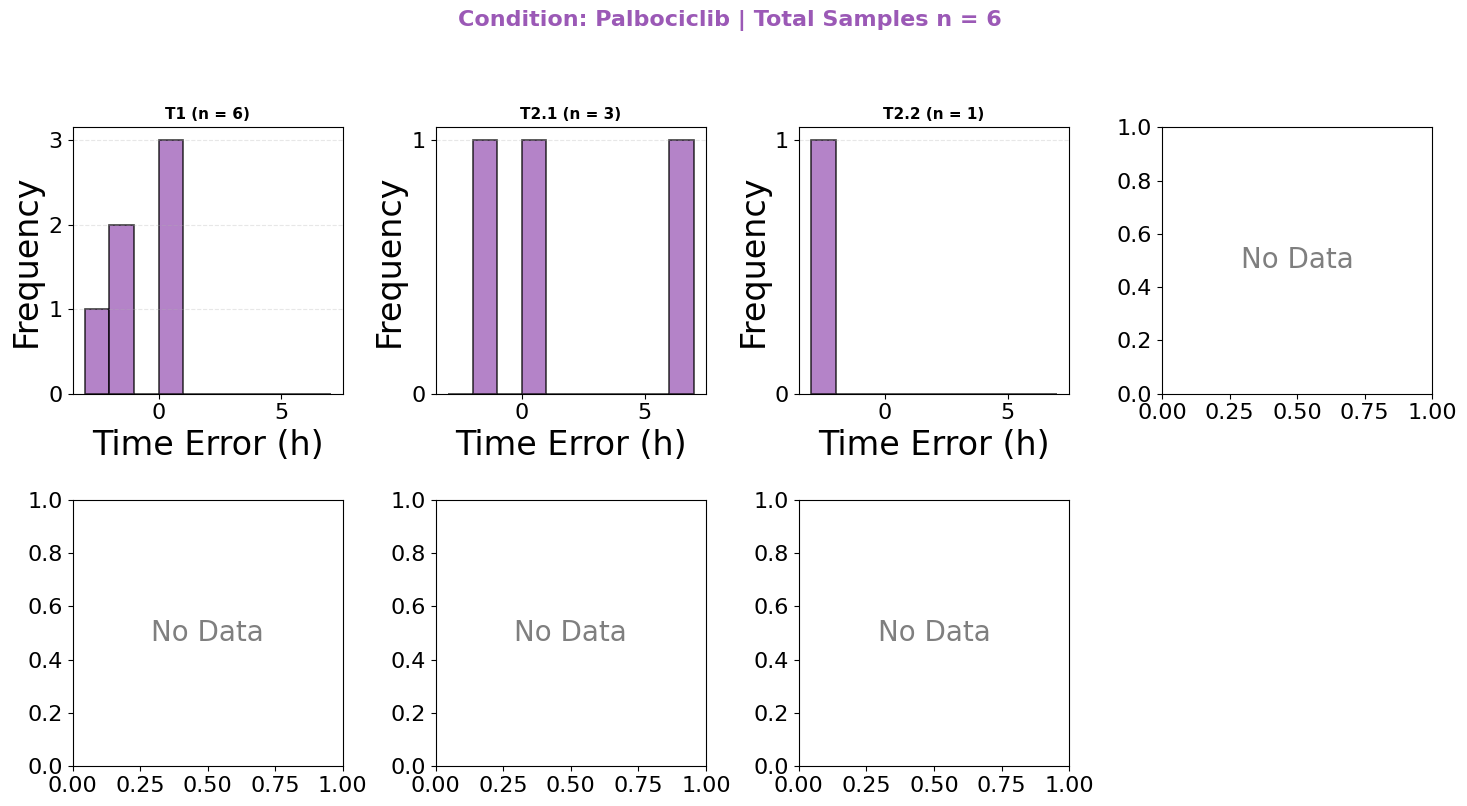

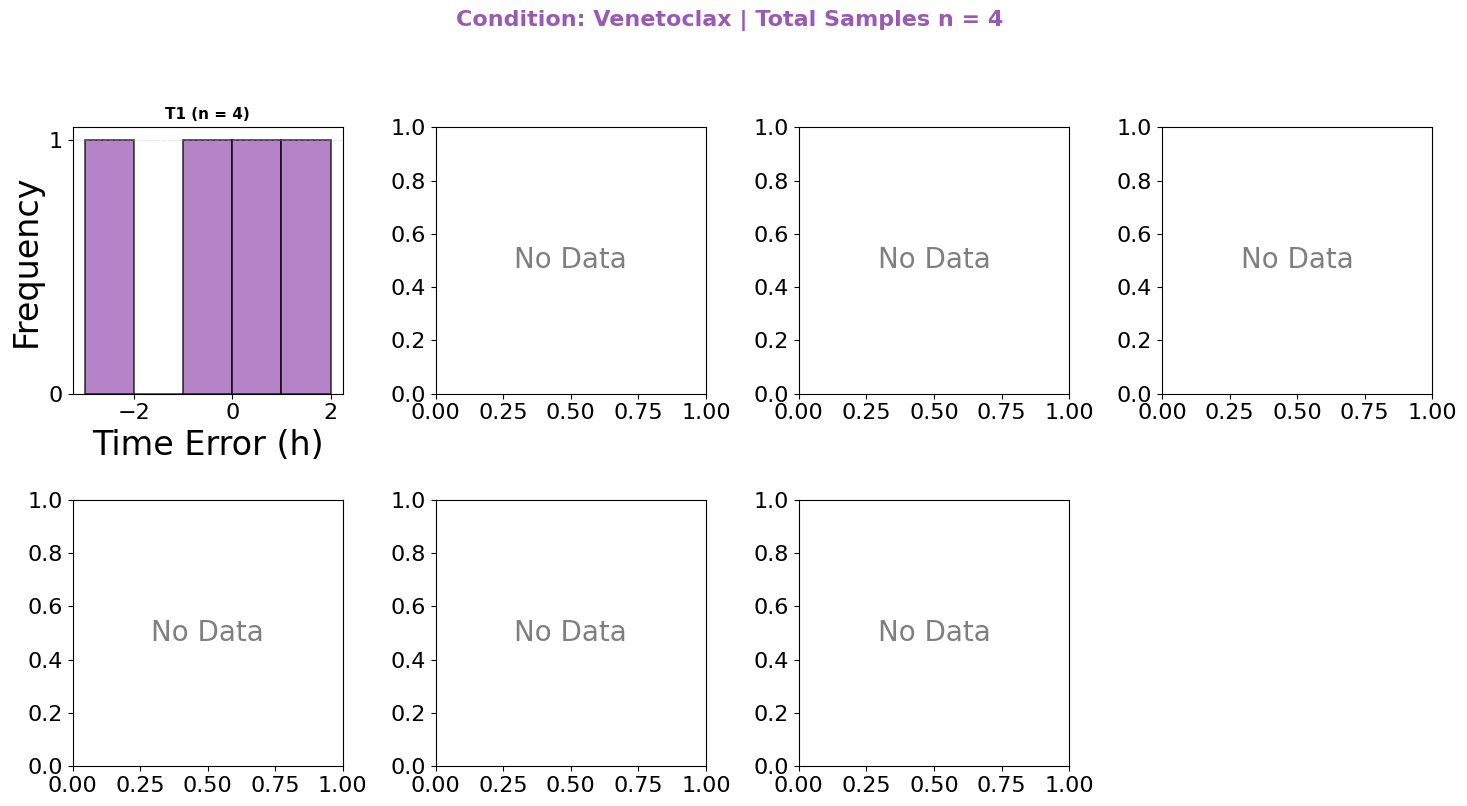

In [30]:
import importlib
import functions.functions_times_benchmark
importlib.reload(functions.functions_times_benchmark)
from functions.functions_times_benchmark import plot_error_histograms

path_save ="Figures"
cols =['T1', 'T2.1', 'T2.2', 'T3.1', 'T3.2', 'T3.3', 'T3.4']
# drop problem due to intruder
idx_max_abs = diff_df["T1"].abs().idxmax()
print(diff_df.loc[idx_max_abs])
diff_df = diff_df.drop(idx_max_abs)
# due problem due to non identification of times
idx_na_t1 = diff_df["T1"].isna()
print(diff_df.loc[idx_na_t1])
diff_df = diff_df.dropna(subset=["T1"])
plot_error_histograms(diff_df, cols=cols, condition_col="Condition", bin_width=1,\
                      plot_title = None,\
                      path_save=path_save, name_fig_global="timeerrorglobal")

In [31]:
import importlib
import functions.functions_times_benchmark
importlib.reload(functions.functions_times_benchmark)
from functions.functions_times_benchmark import compute_error_metrics

metrics = compute_error_metrics(diff_df, cols=cols, print_results=True)

MAE:
 T1      1.462963
T2.1    1.527778
T2.2    1.500000
T3.1    0.807692
T3.2    0.875000
T3.3    1.227273
T3.4    2.166667
dtype: float64

RMSE:
 T1      1.843407
T2.1    1.954340
T2.2    1.821172
T3.1    1.028442
T3.2    1.070436
T3.3    1.438117
T3.4    2.743680
dtype: float64

BIAS:
 T1     -0.759259
T2.1   -0.250000
T2.2   -0.633333
T3.1    0.038462
T3.2   -0.541667
T3.3   -1.045455
T3.4   -0.944444
dtype: float64


27
27


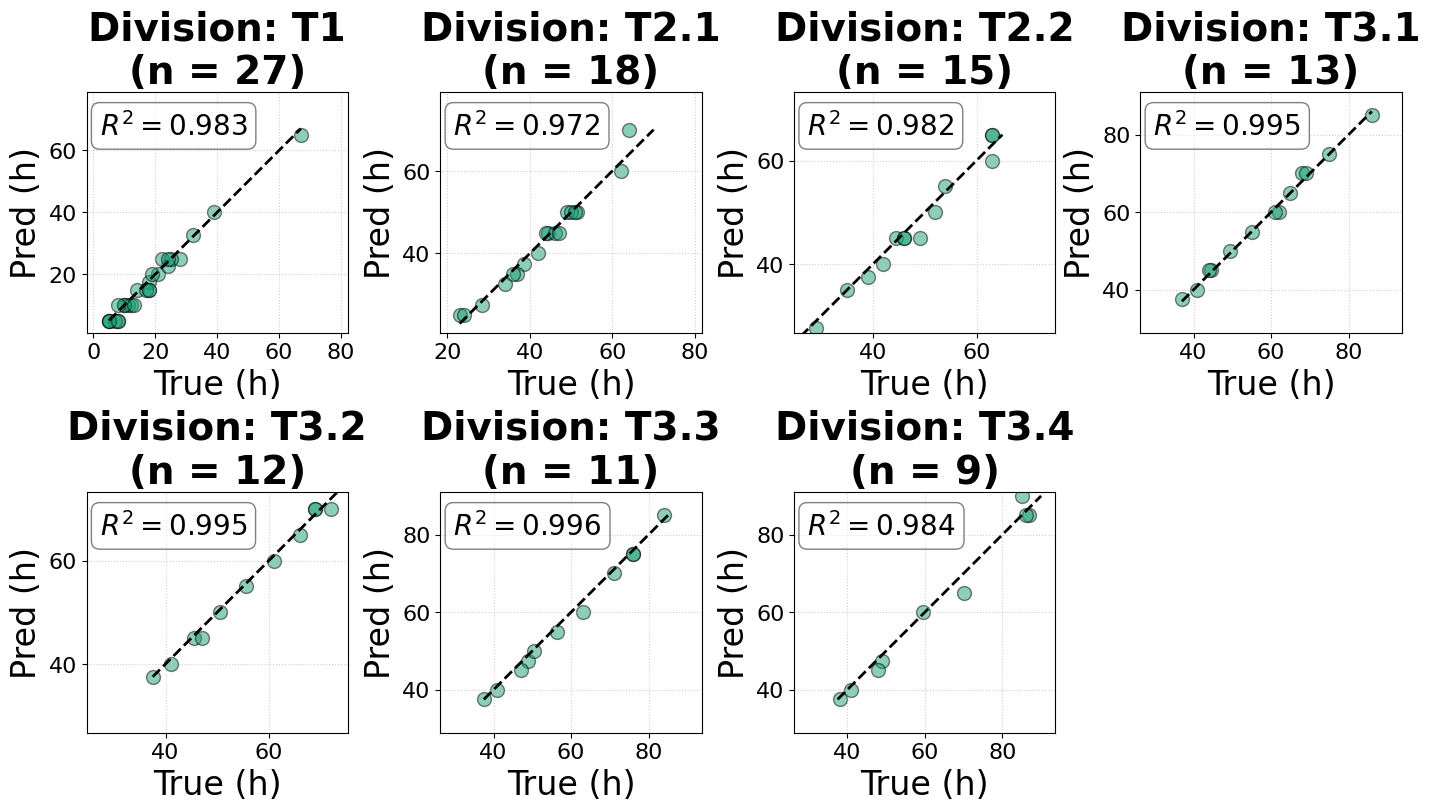

In [32]:
import importlib
import functions.functions_times_benchmark
importlib.reload(functions.functions_times_benchmark)
from functions.functions_times_benchmark import plot_true_vs_predicted


combined_df_matches = combined_df_matches[combined_df_matches["Name"] != "(HPC_3000)_tile008_e2"]
df_pratic_matches = df_pratic_matches[df_pratic_matches["key"] != "(HPC_3000)_tile008_e2"]
combined_df_matches = combined_df_matches[combined_df_matches["Name"] != "TR9-C01_tile008_a4"]
df_pratic_matches = df_pratic_matches[df_pratic_matches["key"] != "TR9-C01_tile008_a4"]
print(len(combined_df_matches))
print(len(df_pratic_matches))

plot_true_vs_predicted(combined_df_matches, df_pratic_matches, cols=cols, plt_title=None, \
                       path_save=path_save, name_file_fig="fig_scatterplotstruevspredicted")

In [33]:
print(combined_df_matches["T1"].min())
print(combined_df_matches["T2.1"].min())
print(combined_df_matches["T2.2"].min())
print(combined_df_matches["T3.1"].max())
print(combined_df_matches["T3.2"].max())
print(combined_df_matches["T3.3"].max())
print(combined_df_matches["T3.4"].max())

5.0
23.0
24.0
86.0
75.0
89.0
87.0


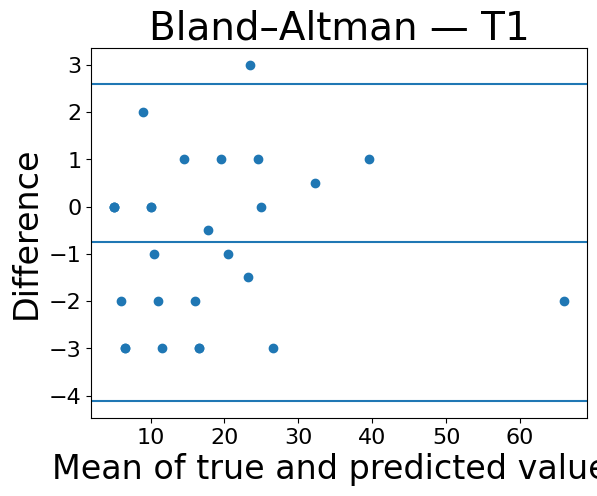

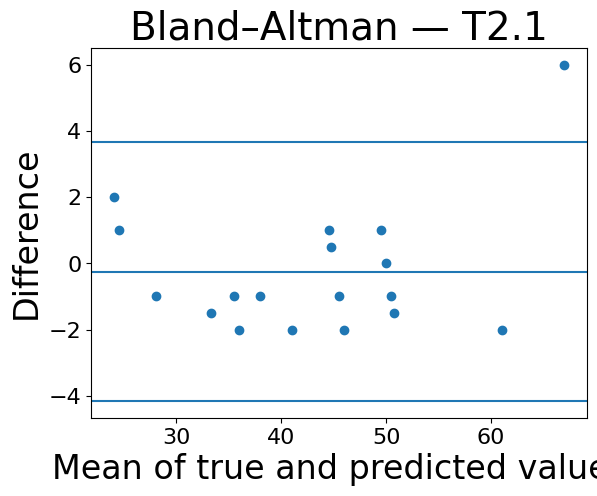

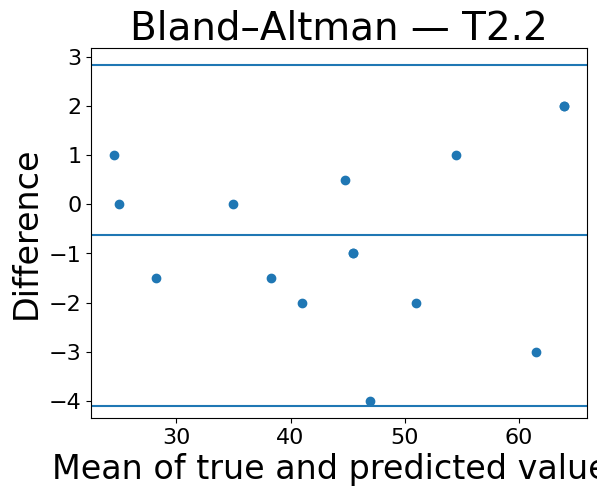

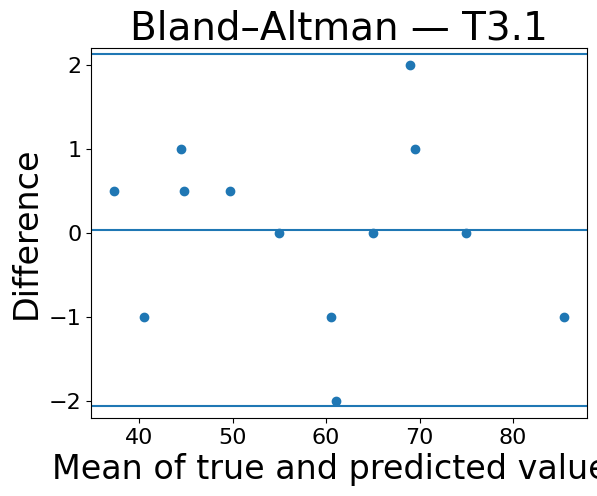

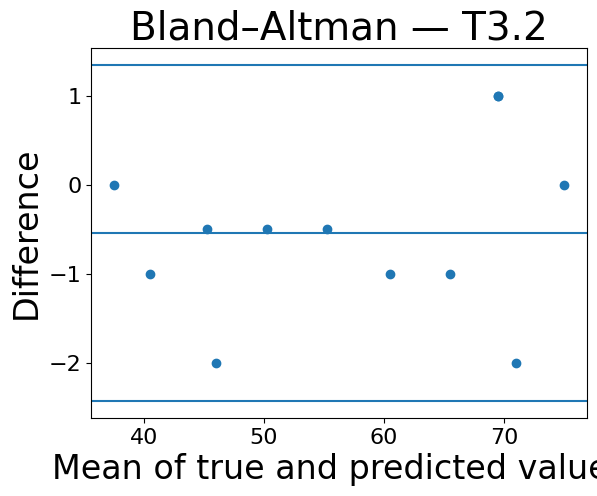

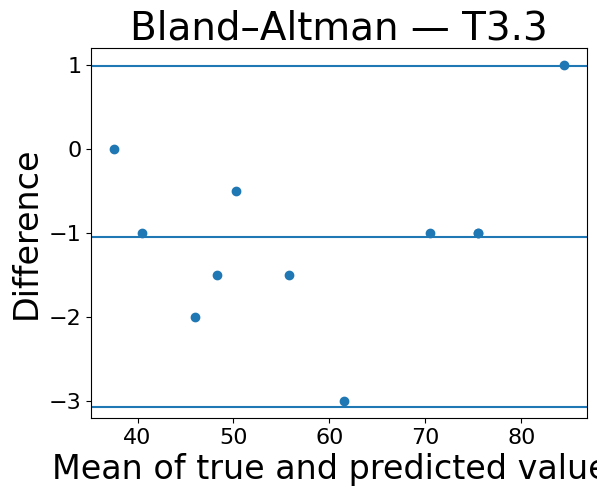

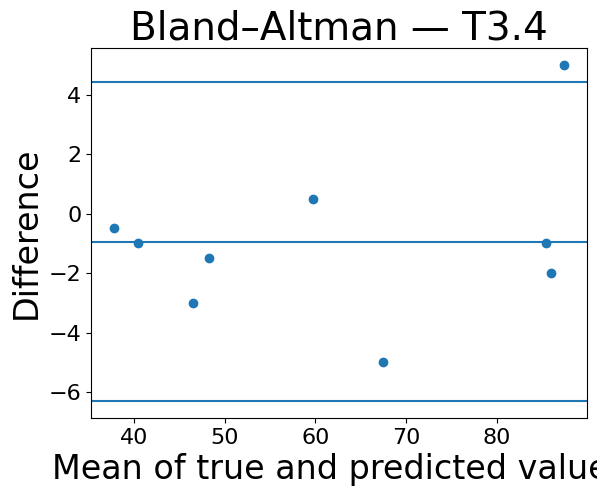

In [34]:
def plot_bland_altman(df_true, df_pred, cols):
    """
    Bland–Altman plot per colonna.
    """

    for col in cols:
        true = df_true[col]
        pred = df_pred[col]

        mean_val = (true + pred) / 2
        diff_val = pred - true

        bias = diff_val.mean()
        sd = diff_val.std()

        plt.figure()
        plt.scatter(mean_val, diff_val)

        plt.axhline(bias)
        plt.axhline(bias + 1.96 * sd)
        plt.axhline(bias - 1.96 * sd)

        plt.xlabel("Mean of true and predicted values")
        plt.ylabel("Difference")
        plt.title(f"Bland–Altman — {col}")
        plt.show()

plot_bland_altman(combined_df_matches, df_pratic_matches, cols=cols)

# Ulterior checks (when no filtering is applied!)

In [35]:
# Find microwells that are in the groundtruth but not in the VisioWell results
# (it may be due to correction that corrects one cell into two cells for example, or visiowell identifies 0 or 2 cells for some reason)
# remember that in the groundtruth sometimes the cell comes not in frame 0, so it's normal that visiowell were not to identify it in frame 1
#print(combined_df["Name"])
#print(combined_df_matches["Name"])
diff_mws = combined_df[~combined_df["Name"].isin(combined_df_matches["Name"])]
diff_mws = diff_mws.reset_index(drop=True)
print(diff_mws)
print(list(diff_mws["Name"]))

                     Name    T1  T2.1  T2.2  T3.1  T3.2  T3.3  T3.4  \
0      TR1-A01_tile176_b4  26.0  67.0  76.0   NaN   NaN   NaN   NaN   
1      TR1-A01_tile163_a2   4.0  25.0  29.0  41.0  42.0  47.0  48.0   
2      TR1-A01_tile068_b4   9.0  22.0  23.0  40.0  41.0  46.0  50.0   
3      TR1-A01_tile051_a1   7.0  28.0  29.0  51.0  52.0  60.0  60.0   
4      TR1-A01_tile003_b2   7.0  26.0  28.0  45.0  46.0  47.0  49.0   
5      TR1-A01_tile037_a3  16.0  42.0  43.0  60.0  64.0  74.0  76.0   
6      TR7-B02_tile005_a3  10.0  45.0   NaN   NaN   NaN   NaN   NaN   
7      TR7-B02_tile002_a4   3.0  52.0  71.0   NaN   NaN   NaN   NaN   
8      TR7-B02_tile080_c3  55.0   NaN   NaN   NaN   NaN   NaN   NaN   
9      TR7-B02_tile115_a2  10.0  38.0  41.0  82.0  83.0   NaN   NaN   
10     TR3-A03_tile180_b2   3.0   NaN   NaN   NaN   NaN   NaN   NaN   
11     TR3-A03_tile004_a1  14.0   NaN   NaN   NaN   NaN   NaN   NaN   
12     TR3-A03_tile057_a2  13.0  60.0   NaN   NaN   NaN   NaN   NaN   
13    